# 04 · Lead scoring, búsqueda del mejor modelo y rentabilidad por canal

**Sesión 4 · Conversión y leads** (ruta Paid Media: lead scoring con gradient boosting, lift por deciles, calidad del lead, optimización de presupuesto).

Preguntas:
1. ¿Se puede ordenar los leads para que ventas atienda primero a los que más cierran? ¿Qué modelo lo hace mejor?
2. ¿Qué pesa más: el canal o la landing page?
3. Con valor y costo, ¿qué canal de pauta rinde más por peso?

Población (decisión 004): leads de 2018; entreno ene–mar, prueba abr–may. Búsqueda: `python -m growth_lab.leads_modelos 40`; score y rentabilidad: `python -m growth_lab.leads`. Todo lee y escribe en `data/processed/`.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from growth_lab import db, leads

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
P = db.PROCESSED
optuna_t = pd.read_parquet(P / "leads_optuna.parquet")
met = pd.read_parquet(P / "leads_metricas.parquet")
dec = pd.read_parquet(P / "leads_deciles.parquet")
imp = pd.read_parquet(P / "leads_importancia.parquet")
score = pd.read_parquet(P / "leads_score.parquet")
rent = pd.read_parquet(P / "canales_rentabilidad.parquet")
estab = pd.read_parquet(P / "leads_estabilidad.parquet")
coef = pd.read_parquet(P / "leads_coeficientes.parquet")
gpu = pd.read_parquet(P / "leads_cpu_vs_gpu.parquet")
print(f"{len(optuna_t)} intentos de Optuna en {optuna_t.modelo.nunique()} modelos")

240 intentos de Optuna en 6 modelos


## 1. La búsqueda: validación temporal (Optuna) vs. prueba final

Izquierda: el AUC de cada intento en la validación temporal dentro de ene–mar. Derecha: el AUC del mejor intento de cada modelo en la prueba (abr–may), medido una sola vez, con IC 90%.

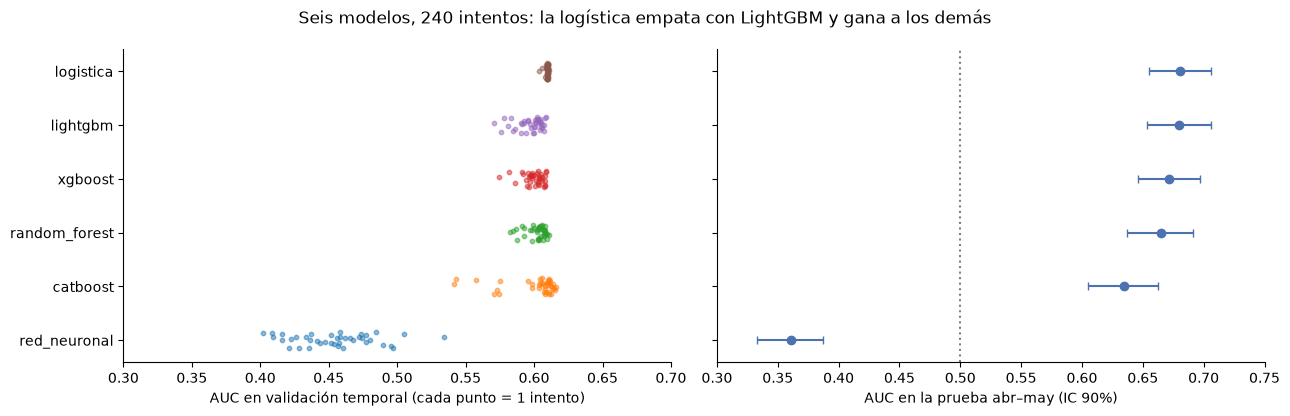

,modelo,auc_temporal,auc,auc_p05,auc_p95,dif_auc_vs_logistica,dif_p05,dif_p95,brier,lift_decil_1,captura_top_20,segundos_entreno
0,logistica,0.6105,0.6805,0.6550,0.7058,0.0000,0.0000,0.0000,0.1009,1.8814,0.3866,0.1142
1,lightgbm,0.6086,0.6800,0.6538,0.7058,-0.0005,-0.0102,0.0092,0.1003,1.8177,0.3930,0.0986
2,xgboost,0.6089,0.6718,0.6457,0.6973,-0.0086,-0.0168,-0.0002,0.1010,1.8814,0.3738,1.1941
3,random_forest,0.6106,0.6646,0.6373,0.6916,-0.0159,-0.0276,-0.0039,0.1018,1.8814,0.3802,1.0543
4,catboost,0.6157,0.6343,0.6050,0.6621,-0.0462,-0.0611,-0.0323,0.1141,1.5944,0.3482,7.3349
5,red_neuronal,0.5343,0.3612,0.3328,0.3874,-0.3193,-0.3693,-0.2692,0.1963,0.5740,0.0927,0.3723


In [2]:
orden = met.sort_values("auc").modelo.tolist()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for i, m in enumerate(orden):
    v = optuna_t[optuna_t.modelo == m].auc_temporal
    a1.scatter(v, np.full(len(v), i) + np.random.default_rng(0).uniform(-.15, .15, len(v)), s=10, alpha=.5)
a1.set_yticks(range(len(orden)), orden); a1.set_xlabel("AUC en validación temporal (cada punto = 1 intento)")
a1.set_xlim(0.3, 0.7)
m2 = met.set_index("modelo").loc[orden]
a2.errorbar(m2.auc, range(len(orden)), xerr=[m2.auc - m2.auc_p05, m2.auc_p95 - m2.auc], fmt="o", capsize=3, color="#4C72B0")
a2.axvline(0.5, color="grey", ls=":"); a2.set_xlabel("AUC en la prueba abr–may (IC 90%)"); a2.set_xlim(0.3, 0.75)
fig.suptitle("Seis modelos, 240 intentos: la logística empata con LightGBM y gana a los demás")
fig.tight_layout(); fig.savefig("../docs/img/leads_modelos.png", dpi=150); plt.show()
cols = ["modelo", "auc_temporal", "auc", "auc_p05", "auc_p95", "dif_auc_vs_logistica", "dif_p05", "dif_p95", "brier", "lift_decil_1", "captura_top_20", "segundos_entreno"]
met[cols].round(4)

**Dos lecciones de la búsqueda:**
- **CatBoost** fue el mejor en la validación temporal (0,616) y el peor de los árboles en la prueba (0,634): con dos cortes chicos, 40 intentos terminan ajustándose al ruido de la validación.
- **La red neuronal** ordena al revés en la prueba (0,36). Las tasas previas se duplican entre entreno y prueba (sección 4) y la red extrapola mal fuera del rango que vio; los árboles y la logística lo toleran.

## 2. ¿Cuánto sirve el score? Deciles y curva de ganancia del campeón (logística)

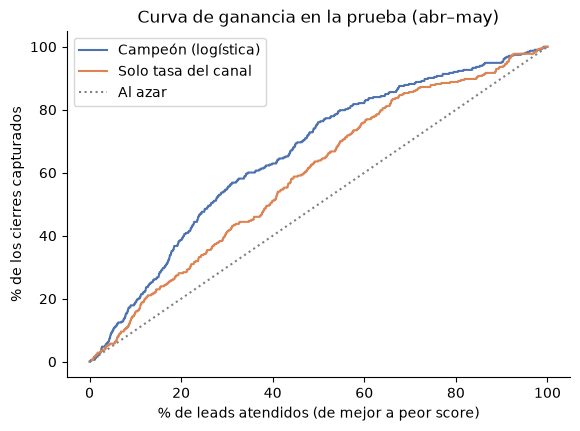

,decil,leads,cierres,tasa_cierre,p_media,lift,captura_acumulada
0,1,266,59,0.222,0.278,1.881,0.188
1,2,266,62,0.233,0.247,1.977,0.387
2,3,266,51,0.192,0.210,1.626,0.550
3,4,266,25,0.094,0.160,0.797,0.629
4,5,266,41,0.154,0.134,1.307,0.760
5,6,265,21,0.079,0.121,0.672,0.827
6,7,265,17,0.064,0.112,0.544,0.882
7,8,265,12,0.045,0.103,0.384,0.920
8,9,265,10,0.038,0.095,0.320,0.952
9,10,265,15,0.057,0.082,0.480,1.000


In [3]:
pr = score[score.muestra == "prueba"]
en = score[score.muestra == "entreno"]
y = pr.cerro.to_numpy(int)
base = pr.canal.map(en.groupby("canal").cerro.mean()).fillna(en.cerro.mean()).to_numpy()  # solo la tasa del canal
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for nombre, p, c in (("Campeón (logística)", pr.p_cierre.to_numpy(), "#4C72B0"), ("Solo tasa del canal", base, "#DD8452")):
    o = np.argsort(-p, kind="stable"); cap = np.cumsum(y[o]) / y.sum()
    ax.plot(np.arange(1, len(y) + 1) / len(y) * 100, cap * 100, label=nombre, color=c)
ax.plot([0, 100], [0, 100], color="grey", ls=":", label="Al azar")
ax.set_xlabel("% de leads atendidos (de mejor a peor score)"); ax.set_ylabel("% de los cierres capturados")
ax.set_title("Curva de ganancia en la prueba (abr–may)"); ax.legend(); plt.show()
dec[dec.modelo == "logistica"].drop(columns="modelo").round(3)

## 3. ¿Qué pesa más? Importancia por permutación y coeficientes del scorecard

In [4]:
t = imp[imp.modelo.isin(["logistica", "lightgbm"])].pivot(index="variable", columns="modelo", values="caida_auc")
display(t.sort_values("logistica", ascending=False).round(4))
print("Atributos que más suman y más restan (log-odds) en la logística:")
pd.concat([coef.head(6), coef.tail(6)])[["atributo", "coeficiente"]].round(3)

modelo,lightgbm,logistica
variable,,
canal,0.0171,0.0382
landing,0.1059,0.0209
landing_leads_previos_log,-0.0003,0.0098
landing_tasa_previa,-0.0005,0.0062
dia_semana,0.0013,0.0054
canal_tasa_previa,-0.0037,0.0015
landing_nueva,0.0000,0.0015
landing_edad_dias,0.0021,-0.0001


Atributos que más suman y más restan (log-odds) en la logística:


,atributo,coeficiente
0,cat__landing_22c29808c4f815213303f8933030604c,0.398
1,cat__canal_unknown,0.396
2,cat__canal_sin_dato,0.309
3,cat__landing_40dec9f3d5259a3d2dbcdab2114fae47,0.239
4,cat__landing_b76ef37428e6799c421989521c0e5077,0.235
5,cat__landing_30077c17f2ec5010a82e37ad8925b95f,0.222
58,cat__landing_73f31a40697cc90a86c1273563ac230e,-0.210
59,cat__canal_referral,-0.218
60,cat__canal_other,-0.228
61,cat__landing_f017be4dbf86243af5c1ebed0cff36a2,-0.229


## 4. Estabilidad: las variables de historia derivan (decisión 005)

PSI > 0,25 = cambio fuerte. La tasa previa se duplica porque los cierres conocidos se acumulan desde dic-2017 (artefacto del dataset). Se mantienen y se monitorean.

In [5]:
estab.round(3)

,variable,media_entreno,media_prueba,psi,alerta
0,landing_leads_previos_log,4.079,4.372,0.375,fuerte
1,landing_tasa_previa,0.040,0.083,2.102,fuerte
2,canal_tasa_previa,0.033,0.074,3.746,fuerte
3,landing_edad_dias,148.765,150.166,1.379,fuerte
4,landing_nueva,0.077,0.075,0.000,estable


## 5. ¿Ayuda la GPU? Medición con los mismos datos

In [6]:
gpu.pivot(index="modelo", columns="dispositivo", values="segundos").round(2)

dispositivo,CPU,GPU
modelo,,
catboost,37.91,47.49
xgboost,0.94,2.42


## 6. Rentabilidad por canal: valor por unidad de costo (pagada = 1)

Costo relativo por conversión del benchmark de atribución (decisión 004). Orgánica y directo son costo fijo y no entran.

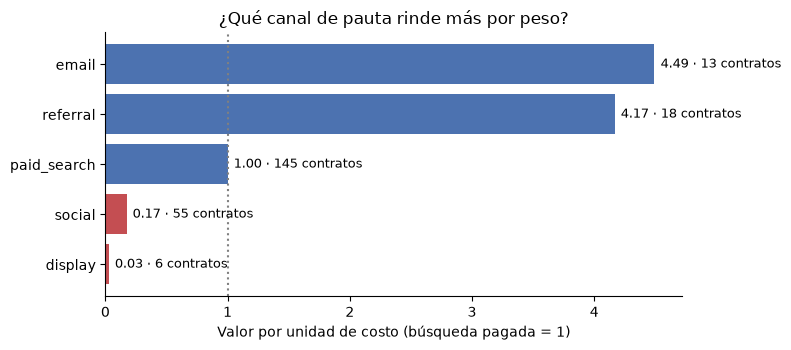

,canal,leads,cerrados_maduros,gmv_por_lead,cpl_equilibrio,indice_costo,tipo_costo,valor_relativo_por_costo
0,organic_search,2296,206,51.886,7.783,0.000,fijo,NaN
1,paid_search,1586,145,63.165,9.475,1.000,por_lead,1.000
2,social,1350,55,12.896,1.934,1.182,por_lead,0.173
3,unknown,1099,153,137.176,20.576,NaN,sin_dato,NaN
4,direct_traffic,499,49,20.568,3.085,0.000,fijo,NaN
5,email,493,13,14.346,2.152,0.051,por_lead,4.493
6,referral,284,18,53.900,8.085,0.205,por_lead,4.168
7,other,150,4,35.227,5.284,NaN,sin_dato,NaN
8,display,118,6,2.314,0.347,1.323,por_lead,0.028
9,other_publicities,65,3,0.000,0.000,NaN,sin_dato,NaN


In [7]:
r = rent[rent.tipo_costo == "por_lead"].sort_values("valor_relativo_por_costo")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(r.canal, r.valor_relativo_por_costo, color=["#C44E52" if v < 1 else "#4C72B0" for v in r.valor_relativo_por_costo])
for i, (v, n) in enumerate(zip(r.valor_relativo_por_costo, r.cerrados_maduros)):
    ax.text(v + 0.05, i, f"{v:.2f} · {n} contratos", va="center", fontsize=9)
ax.axvline(1, color="grey", ls=":"); ax.set_xlabel("Valor por unidad de costo (búsqueda pagada = 1)")
ax.set_title("¿Qué canal de pauta rinde más por peso?")
fig.tight_layout(); fig.savefig("../docs/img/canales_valor_costo.png", dpi=150); plt.show()
rent[["canal", "leads", "cerrados_maduros", "gmv_por_lead", "cpl_equilibrio", "indice_costo", "tipo_costo", "valor_relativo_por_costo"]].round(3)

## Mis conclusiones (Neider)

1. **Me quedo con la logística.** Probé 6 modelos con 240 intentos de Optuna: la logística saca 0,681 en abr–may, empata con LightGBM (0,680) y le gana a XGBoost, Random Forest y CatBoost. Con un empate, gana lo simple.
2. **El score sirve para priorizar:** el 20% de leads con mejor score trae el 39% de los cierres, y el 30% trae el 55%. Ventas puede empezar por ahí.
3. **Más complejo no es mejor:** CatBoost fue el mejor en la validación y el peor de los árboles en la prueba (se ajustó al ruido), y la red neuronal ordenó al revés porque las tasas previas se duplicaron entre entreno y prueba.
4. **Las landings importan:** su tasa de cierre va de 4–8% a 22–23% y se mantiene en el tiempo (correlación 0,87 entre períodos); en los modelos de árboles la landing es lo que más pesa. Quiero mandar más tráfico a las mejores y confirmarlo con un A/B en la sesión 6, porque cada landing puede atraer un público distinto.
5. **Pauta:** muevo presupuesto de social (0,17 de valor por unidad de costo frente a búsqueda pagada) y display (0,03) hacia búsqueda pagada. E-mail (4,5) y referidos (4,2) se ven más eficientes, pero con 13 y 18 contratos: los escalo con una prueba controlada. Los costos salen del benchmark, no de Olist.
6. **La GPU no siempre ayuda:** con 3.300 leads la CPU fue más rápida.